> **学生作业版说明**  
> 本 Notebook 为学生作业版，部分关键代码单元已被替换为待补全骨架。  
> 请结合 `README.md`、`assignment.md` 与 `starter.py` 完成实验。  
> 提交前请确认：代码可运行、指标齐全、报告完整。

### 概述
&ensp;&ensp;本实验介绍Softmax回归算法具体应用。

### 实验环境
+ Ubuntu
+ Jupyter NoteBook

### 实验目标
完成本实验后，您能够

1. 通过本实验进一步掌握Softmax回归算法的原理。
2. 掌握如何使用Softmax回归算法解决实际问题。
3. 掌握使用机器学习方法解决现实世界问题的流程。

### 任务：Softmax回归
#### 【任务内容】
    奥托集团是世界上最大的电子商务公司之一，在20多个国家拥有子公司，包括美国的Crate & Barrel，德国的Otto.de和法国的3 Suisse。我们每天在全球销售数以百万计的产品，其中有几千种产品加入到我们的产品线中。
    对我们产品性能的一致分析是至关重要的。然而，由于我们多元化的全球基础设施，许多相同的产品被分类不同。因此，我们产品分析的质量在很大程度上依赖于对相似产品进行准确聚类的能力。分类越好，我们对产品范围的了解就越多。
    我们为超过200,000个产品提供了包含93个特性的数据集。我们的目标是建立一个能够区分我们主要产品类别的预测模型。
#### 【任务目标】
    使用Softmax回归来解决奥托产品分类问题
#### 【任务步骤】
1. 传入特征组和标签，以及学习率和搜索步数
2. 模型训练
3. 使用测试集进行预测
4. 输出准确率

In [1]:
#倒入相关库文件
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

In [2]:
import os, urllib.request
if not os.path.exists('data.csv'):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/Heptazero/ml-course-labs/main/machine-learning/homework/data.csv', 'data.csv')

In [3]:
#首先我们先观察一下数据的总体描述
data = pd.read_csv('data.csv')
data.describe(include='all')

,id,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_85,feat_86,feat_87,feat_88,feat_89,feat_90,feat_91,feat_92,feat_93,target
count,61878.000000,61878.00000,61878.000000,61878.000000,61878.000000,61878.000000,61878.000000,61878.000000,61878.000000,61878.000000,...,61878.000000,61878.000000,61878.000000,61878.000000,61878.000000,61878.000000,61878.000000,61878.000000,61878.000000,61878
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Class_2
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16122
mean,30939.500000,0.38668,0.263066,0.901467,0.779081,0.071043,0.025696,0.193704,0.662433,1.011296,...,0.532306,1.128576,0.393549,0.874915,0.457772,0.812421,0.264941,0.380119,0.126135,NaN
std,17862.784315,1.52533,1.252073,2.934818,2.788005,0.438902,0.215333,1.030102,2.255770,3.474822,...,1.900438,2.681554,1.575455,2.115466,1.527385,4.597804,2.045646,0.982385,1.201720,NaN
min,1.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,15470.250000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
50%,30939.500000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
75%,46408.750000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN


In [4]:
#观察数据的任意五行
data.sample(5)

,id,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_85,feat_86,feat_87,feat_88,feat_89,feat_90,feat_91,feat_92,feat_93,target
22122,22123,0,0,0,0,1,0,0,0,0,...,1,1,2,2,0,0,0,0,0,Class_3
1486,1487,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,3,2,0,0,Class_1
11448,11449,0,0,0,0,0,0,0,0,0,...,3,0,0,0,0,0,0,0,0,Class_2
559,560,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Class_1
24265,24266,0,0,0,0,0,0,0,4,3,...,0,1,1,2,0,0,0,0,0,Class_3


数据集一共61878行95列（包括上述特征和target）
由于target是字符型变量，我们画图展示，代码如下：

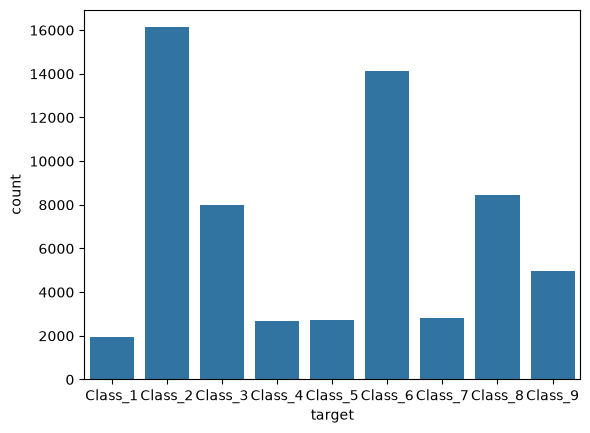

In [5]:
sns.countplot(x=data["target"])
plt.show()

In [6]:
print(data['target'].value_counts().sort_index())

target
Class_1     1929
Class_2    16122
Class_3     8004
Class_4     2691
Class_5     2739
Class_6    14135
Class_7     2839
Class_8     8464
Class_9     4955
Name: count, dtype: int64


In [7]:
#target一共9个类别。由于是字符型，定义一个函数将target的类别标签转为index表示，方便后面计算交叉熵
def target2idx(targets):
    target_idx = []
    target_labels = ['Class_1', 'Class_2', 'Class_3', 'Class_4', 'Class_5', 'Class_6', 'Class_7', 'Class_8', 'Class_9','Class_10']
    for target in targets:
        target_idx.append(target_labels.index(target))
    return target_idx

#向量转化函数(提供参考，自行选择是否使用)
def convert_to_vectors(c):
    m = len(c)
    k = np.max(c) + 1
    y = np.zeros(m * k).reshape(m,k)
    for i in range(m):
        y[i][c[i]] = 1
    return y

#特征处理函数(提供参考，自行选择是否使用)
def process_features(X):
    scaler = MinMaxScaler(feature_range=(0,1))
    X = scaler.fit_transform(1.0*X)
    m, n = X.shape
    X = np.c_[np.ones((m, 1)), X] 
    return X

In [8]:
#数据获取样例，可自行处理
X = np.array(data)[:,1:-1].astype(float)
c = target2idx(data['target'])
y = convert_to_vectors(c)
#划分训练集和测试集比例在0.1-0.9之间
X_train, X_test, y_train, y_test, c_train, c_test = train_test_split(X, y, c, random_state = 0, test_size = 0.2)

lr = 0.1  最后一轮训练损失 1.4295，测试集准确率 0.5646


lr = 1    最后一轮训练损失 0.9242，测试集准确率 0.7013


lr = 5    最后一轮训练损失 0.7476，测试集准确率 0.7342


lr = 10   最后一轮训练损失 0.7056，测试集准确率 0.7414


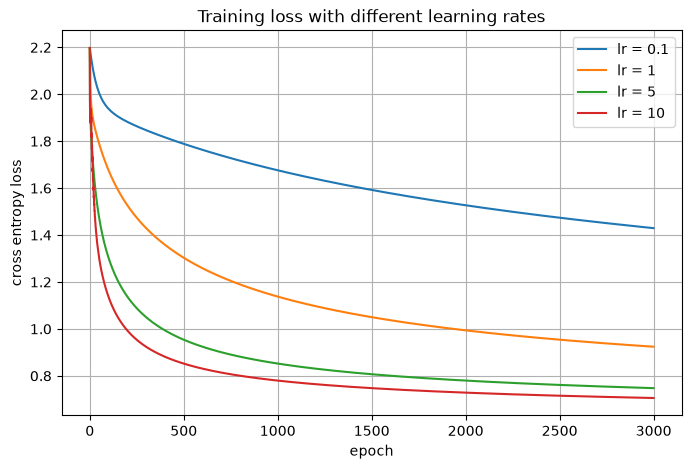

训练损失最小的学习率： 10


In [9]:
#模型训练及预测
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

class SoftmaxRegression:
    def __init__(self, lr=0.1, epochs=1000):
        self.lr = lr
        self.epochs = epochs
        self.W = None
        self.loss_history = []

    def fit(self, X, y):
        m, n = X.shape
        self.W = np.zeros((n, y.shape[1]))
        self.loss_history = []
        for epoch in range(self.epochs):
            H = softmax(X.dot(self.W))
            self.loss_history.append(-np.sum(y * np.log(H + 1e-12)) / m)
            self.W -= self.lr * X.T.dot(H - y) / m

    def predict_proba(self, X):
        return softmax(X.dot(self.W))

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

scaler = MinMaxScaler(feature_range=(0, 1)).fit(X_train)
X_train_p = np.c_[np.ones((len(X_train), 1)), scaler.transform(X_train)]
X_test_p = np.c_[np.ones((len(X_test), 1)), scaler.transform(X_test)]

models = {}
for lr in [0.1, 1, 5, 10]:
    model = SoftmaxRegression(lr=lr, epochs=3000)
    model.fit(X_train_p, y_train)
    models[lr] = model
    acc = accuracy_score(c_test, model.predict(X_test_p))
    print('lr = %-4s 最后一轮训练损失 %.4f，测试集准确率 %.4f' % (lr, model.loss_history[-1], acc))

plt.figure(figsize=(8, 5))
for lr, model in models.items():
    plt.plot(model.loss_history, label='lr = %s' % lr)
plt.xlabel('epoch')
plt.ylabel('cross entropy loss')
plt.title('Training loss with different learning rates')
plt.legend()
plt.grid(True)
plt.show()

best_lr = min(models, key=lambda lr: models[lr].loss_history[-1])
print('训练损失最小的学习率：', best_lr)
c_pred = models[best_lr].predict(X_test_p)

In [10]:
#计算指标，本指标使用加权的方式计算多分类问题，accuracy和recall相等，可将其原因写入报告
accuracy = accuracy_score(c_test, c_pred)
precision = precision_score(c_test, c_pred,average = 'weighted')
recall = recall_score(c_test, c_pred,average = 'weighted')
f1 = f1_score(c_test, c_pred,average = 'weighted')
print("accuracy = {}".format(accuracy))
print("precision = {}".format(precision))
print("recall = {}".format(recall))
print("f1 = {}".format(f1))

accuracy = 0.7414350355526826
precision = 0.7402276070490499
recall = 0.7414350355526826
f1 = 0.7135381092461046


### 补充：每个类别的结果

              precision    recall  f1-score   support

     Class_1     0.5912    0.2189    0.3195       370
     Class_2     0.6128    0.8952    0.7275      3205
     Class_3     0.5114    0.2464    0.3326      1546
     Class_4     0.8235    0.1484    0.2515       566
     Class_5     0.9190    0.9004    0.9096       542
     Class_6     0.9163    0.9224    0.9193      2823
     Class_7     0.6915    0.4703    0.5598       572
     Class_8     0.8101    0.9096    0.8570      1703
     Class_9     0.8214    0.8112    0.8163      1049

    accuracy                         0.7414     12376
   macro avg     0.7441    0.6136    0.6326     12376
weighted avg     0.7402    0.7414    0.7135     12376



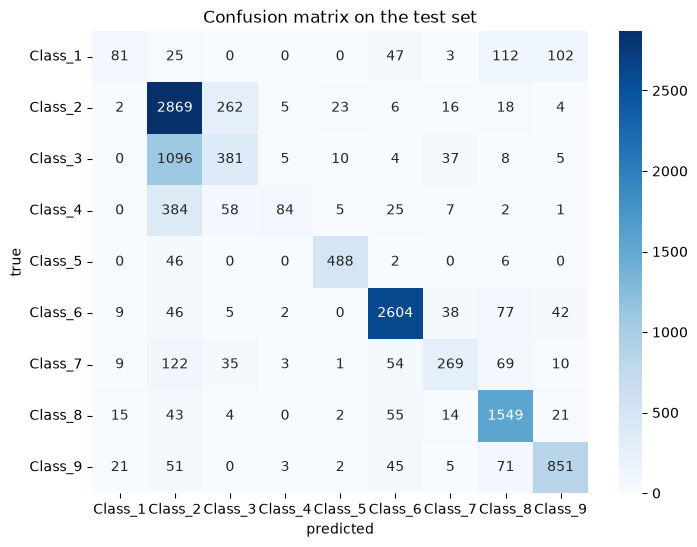

In [11]:
from sklearn.metrics import confusion_matrix, classification_report
class_names = ['Class_%d' % k for k in range(1, 10)]
print(classification_report(c_test, c_pred, target_names=class_names, digits=4))

cm = confusion_matrix(c_test, c_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('predicted')
plt.ylabel('true')
plt.title('Confusion matrix on the test set')
plt.show()